# Colorado groundwater levels (USGS)

Mirrors the `snow_pack` notebook, but for USGS groundwater level data in Colorado.

Uses the **USGS Water Data OGC API** (`api.waterdata.usgs.gov`). The legacy `waterservices.usgs.gov` endpoints (`/iv`, `/dv`) are scheduled for decommission in early 2027 and `gwlevels` is already gone, so this avoids them.

- Parameter `72019` = depth to water level, **feet below land surface**. Bigger number = deeper water = falling water table, so the plots invert the y-axis.
- Collections used: `monitoring-locations`, `time-series-metadata`, `daily`, `continuous`, `field-measurements`, `latest-daily`, `latest-continuous`.
- Optional: set a free API key in the `USGS_API_KEY` environment variable for higher rate limits (https://api.waterdata.usgs.gov/signup).

In [1]:
import os
import json
import time
import hashlib
import requests
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date, timedelta
from pathlib import Path

def load_env(name=".env"):
    """Find .env in the working dir or any parent, load its KEY=VALUE lines into os.environ."""
    for d in [Path.cwd(), *Path.cwd().parents]:
        f = d / name
        if f.is_file():
            for line in f.read_text(encoding="utf-8-sig").splitlines():
                line = line.strip()
                if not line or line.startswith("#") or "=" not in line:
                    continue
                k, v = line.split("=", 1)
                if not os.environ.get(k.strip()):
                    os.environ[k.strip()] = v.strip().strip('"').strip("'")
            return f
    return None

ENV_FILE = load_env()
print(".env:", ENV_FILE or "NOT FOUND (looked in cwd and its parents)", "| cwd:", Path.cwd())

.env: C:\Users\lilli\work\classes\gpgn438-design-drought-analysis\inital_data_exploration\.env | cwd: C:\Users\lilli\work\classes\gpgn438-design-drought-analysis\inital_data_exploration


In [2]:
BASE_URL = "https://api.waterdata.usgs.gov/ogcapi/v0"
API_KEY = os.environ.get("USGS_API_KEY") or None  # optional; blank counts as unset
GW_PARAM = "72019"  # depth to water level, ft below land surface

def chunks(seq, n):
    seq = list(seq)
    for i in range(0, len(seq), n):
        yield seq[i:i + n]

MIN_INTERVAL = 0.5 if API_KEY else 1.5   # seconds between requests (be gentler without a key)
CACHE_DIR = Path(".cache"); CACHE_DIR.mkdir(exist_ok=True)
_last_call = [0.0]

def _get_json(url, query, headers, retries=8, use_cache=True):
    """GET with throttling, exponential backoff on 429/5xx (honors Retry-After), and a disk cache."""
    key = hashlib.md5(f"{url}|{sorted((query or {}).items())}".encode()).hexdigest()
    cache_file = CACHE_DIR / f"{key}.json"
    if use_cache and cache_file.exists() and time.time() - cache_file.stat().st_mtime < 6 * 3600:
        return json.loads(cache_file.read_text())

    for attempt in range(retries):
        wait = MIN_INTERVAL - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        resp = requests.get(url, params=query, headers=headers, timeout=60)
        _last_call[0] = time.time()
        if resp.status_code in (429, 500, 502, 503, 504):
            delay = float(resp.headers.get("Retry-After", min(2 ** attempt * 2, 120)))
            print(f"  HTTP {resp.status_code}; sleeping {delay:.0f}s (attempt {attempt + 1}/{retries})")
            time.sleep(delay)
            continue
        if resp.status_code >= 400:
            raise requests.HTTPError(f"{resp.status_code} for {resp.url}\n{resp.text[:600]}", response=resp)
        js = resp.json()
        if use_cache:
            cache_file.write_text(json.dumps(js))
        return js
    resp.raise_for_status()  # out of retries: raise the last error

def ogc_get(collection, max_pages=100, **params):
    """GET /collections/{collection}/items, follow pagination, return a DataFrame.
    Feature properties become columns; point geometry becomes longitude/latitude;
    the feature id is kept as `feature_id`."""
    clean = {}
    for k, v in params.items():
        if v is None:
            continue
        if isinstance(v, bool):
            v = str(v).lower()
        elif isinstance(v, (list, tuple)):
            v = ",".join(map(str, v))
        clean[k] = v
    clean.setdefault("f", "json")
    clean.setdefault("limit", 10000)

    headers = {"X-Api-Key": API_KEY} if API_KEY else {}
    url, query = f"{BASE_URL}/collections/{collection}/items", clean
    rows, pages = [], 0
    while url and pages < max_pages:
        js = _get_json(url, query, headers)
        for feat in js.get("features", []):
            row = dict(feat.get("properties") or {})
            row["feature_id"] = feat.get("id")
            geom = feat.get("geometry") or {}
            if geom.get("type") == "Point":
                row["longitude"], row["latitude"] = geom["coordinates"][:2]
            rows.append(row)
        # the "next" link already carries the full query string
        url = next((l["href"] for l in js.get("links", []) if l.get("rel") == "next"), None)
        query = None
        pages += 1
    return pd.DataFrame(rows)

print("Ready. Base URL:", BASE_URL, "| API key set:", bool(API_KEY))

Ready. Base URL: https://api.waterdata.usgs.gov/ogcapi/v0 | API key set: True


## 1. Find Colorado groundwater sites

In [3]:
def find_gw_sites(state_name="Colorado", site_type_code="GW", **extra):
    """All monitoring locations of a given site type (GW = groundwater well) in a state."""
    df = ogc_get("monitoring-locations", state_name=state_name,
                 site_type_code=site_type_code, **extra)
    if "monitoring_location_id" not in df.columns:
        df["monitoring_location_id"] = df["feature_id"]
    return df

co_sites = find_gw_sites()
print(f"{len(co_sites)} Colorado groundwater monitoring locations")
show = [c for c in ["monitoring_location_id", "monitoring_location_name", "altitude",
                    "latitude", "longitude"] if c in co_sites.columns]
co_sites[show].head(10)

28727 Colorado groundwater monitoring locations


,monitoring_location_id,monitoring_location_name,altitude,latitude,longitude
0,USEPA-371226107471402,NB03400818CA,NaN,37.207222,-107.787222
1,USEPA-371618107594201,NB035010019DDB,NaN,37.271667,-107.995000
2,USEPA-380549107453301,NB04400805AD,NaN,38.096944,-107.759167
3,USEPA-390943108081601,SC01009629BD,NaN,39.161944,-108.137778
4,USEPA-393939106400601,SC00408334AD,NaN,39.660833,-106.668333
5,USEPA-401524106500301,NB00308405DC,NaN,40.256667,-106.834167
6,USFS-390021107505801,LEON LAKE 5 MW,8825.0,39.005800,-107.849431
7,USGS-365946105413901,01N.74W.32.343,7458.0,36.996111,-105.694167
8,USGS-365947105374001,01N.74W.35.444,7573.0,36.996409,-105.628345
9,USGS-365958105403001,CB00107433DAA 01N.74W.33.422,7500.0,37.001270,-105.664985


## 2. Which sites actually have a water-level time series?

`time-series-metadata` tells us the period of record (`begin`/`end`) per series, so we can find wells that are still reporting.

In [4]:
def find_gw_series(site_ids, parameter_code=GW_PARAM, per_request=50):
    frames = []
    n_req = 2 * -(-len(site_ids) // per_request)
    print(f"Querying {len(site_ids)} sites in {n_req} requests (cached after first run)")
    # daily/continuous sensor series AND manual (field) measurement series
    for coll, tag in (("time-series-metadata", "sensor"), ("field-measurements-metadata", "manual")):
        for chunk in chunks(site_ids, per_request):
            try:
                f = ogc_get(coll, monitoring_location_id=chunk,
                            parameter_code=parameter_code, skipGeometry=True)
            except requests.HTTPError as e:
                print(f"  {coll}: {e.response.status_code} for a chunk, skipping")
                continue
            if not f.empty:
                f["series_source"] = tag
                frames.append(f)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

# Colorado has thousands of GW sites. Set MAX_SITES = None for the full statewide pass
# (many requests; get an API key first), or keep a small number while developing.
MAX_SITES = 500
site_pool = co_sites["monitoring_location_id"].drop_duplicates()
if MAX_SITES:
    site_pool = site_pool.head(MAX_SITES)
gw_series = find_gw_series(site_pool.tolist())
if gw_series.empty:
    raise RuntimeError(
        f"No {GW_PARAM} series found for the {len(site_pool)} sites checked. "
        "Increase MAX_SITES (or set it to None), or check the parameter code against "
        "https://api.waterdata.usgs.gov/ogcapi/v0/collections/time-series-metadata/items?monitoring_location_id=<ID>&f=json")

print("gw_series columns:", list(gw_series.columns))
def _find_col(df, *names):
    low = {c.lower(): c for c in df.columns}
    return next((low[n] for n in names if n in low), None)

b_col = _find_col(gw_series, "begin", "begin_utc", "start", "first_observation")
e_col = _find_col(gw_series, "end", "end_utc", "last_observation")
if b_col is None or e_col is None:
    raise KeyError(f"Can't find begin/end columns; available: {list(gw_series.columns)}")
gw_series = gw_series.rename(columns={b_col: "begin", e_col: "end"})
for c in ("begin", "end"):
    gw_series[c] = pd.to_datetime(gw_series[c], utc=True, errors="coerce")
print(gw_series["series_source"].value_counts().to_string())

print(f"{len(gw_series)} series across {gw_series['monitoring_location_id'].nunique()} sites")
if "computation_identifier" in gw_series.columns:
    print(gw_series["computation_identifier"].value_counts())

gw_summary = (gw_series.groupby("monitoring_location_id")
              .agg(begin=("begin", "min"), end=("end", "max"), n_series=("begin", "size"),
                   has_sensor=("series_source", lambda s: bool((s == "sensor").any())))
              .reset_index()
              .merge(co_sites[show], on="monitoring_location_id", how="left"))
gw_summary["record_years"] = (gw_summary["end"] - gw_summary["begin"]).dt.days / 365.25
gw_summary.sort_values("end", ascending=False).head(10)

Querying 500 sites in 20 requests (cached after first run)
gw_series columns: ['id', 'reading_type', 'monitoring_location_id', 'parameter_code', 'parameter_name', 'parameter_description', 'begin', 'end', 'last_modified', 'sublocation_identifier', 'feature_id', 'series_source']
series_source
manual    401
401 series across 401 sites


,monitoring_location_id,begin,end,n_series,has_sensor,monitoring_location_name,altitude,latitude,longitude,record_years
319,USGS-370757105564702,2017-12-05 16:43:00+00:00,2024-09-20 21:00:00+00:00,1,False,NA03300901BCB CON 3-B,7748.08,37.132361,-105.946389,6.792608
318,USGS-370757105564701,2017-12-05 16:43:00+00:00,2024-09-20 20:55:00+00:00,1,False,NA03300901BCB CON 3-A,7748.08,37.132361,-105.946389,6.792608
246,USGS-370640105455501,2023-10-10 19:06:00+00:00,2024-09-11 18:06:00+00:00,1,False,NA03301110DDC RG88,7447.40,37.104889,-105.745333,0.919918
113,USGS-370325105575201,2023-10-10 18:25:00+00:00,2024-09-11 17:25:00+00:00,1,False,NA03300934DAA RG96A,7820.80,37.057139,-105.964917,0.919918
117,USGS-370326105575401,2023-10-10 18:27:00+00:00,2024-09-11 17:23:00+00:00,1,False,NA03300934DAA2 RG96B,7820.50,37.057139,-105.965083,0.919918
118,USGS-370326105575501,2023-10-10 18:23:00+00:00,2024-09-11 17:21:00+00:00,1,False,NA03300934DAA3 RG96C,7820.90,37.057139,-105.965194,0.919918
344,USGS-370815106011201,2023-10-10 17:42:00+00:00,2024-09-10 21:31:00+00:00,1,False,NA03400931DDD RG86,7833.80,37.137611,-106.020278,0.919918
323,USGS-370758105564401,2023-10-10 17:25:00+00:00,2024-09-10 21:15:00+00:00,1,False,NA03300901BCB RG87,7747.10,37.132278,-105.946389,0.919918
216,USGS-370606105574801,1975-01-01 12:00:00+00:00,2024-07-17 16:53:00+00:00,1,False,NA03300914BCC,7793.00,37.101429,-105.964549,49.541410
143,USGS-370418105575201,1974-12-01 12:00:00+00:00,2024-07-17 16:30:00+00:00,1,False,NA03300927ADD,7815.00,37.071874,-105.964937,49.626283


In [5]:
# Find wells that are actually reporting now. Asking the latest-* collections for everything
# inside Colorado's bounding box returns only live sensors, in a handful of requests.
CO_BBOX = (-109.06, 36.99, -102.04, 41.00)   # lon_min, lat_min, lon_max, lat_max
LATEST_COLS = ["monitoring_location_id", "latest_time", "latest_depth_ft", "source"]

def _latest_table(df, source):
    df = df.copy()
    df["time"] = pd.to_datetime(df["time"], utc=True)
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = df.rename(columns={"time": "latest_time", "value": "latest_depth_ft"})
    df["source"] = source
    return df[LATEST_COLS].dropna(subset=["latest_depth_ft"])

def find_active_sensors(bbox=CO_BBOX, max_age_days=30):
    frames = []
    for coll in ("latest-continuous", "latest-daily"):
        try:
            f = ogc_get(coll, parameter_code=GW_PARAM, bbox=bbox)
        except requests.HTTPError as err:
            print(f"  {coll}: {err}")
            continue
        print(f"  {coll}: {len(f)} rows")
        if not f.empty:
            frames.append(_latest_table(f, coll))
    if not frames:
        return pd.DataFrame(columns=LATEST_COLS)
    df = (pd.concat(frames, ignore_index=True)
          .sort_values("latest_time", ascending=False)
          .drop_duplicates("monitoring_location_id"))
    return df[df["latest_time"] >= pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=max_age_days)]

def find_recent_manual(bbox=CO_BBOX, days=365):
    begin = (date.today() - timedelta(days=days)).isoformat()
    end = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ")
    try:
        f = ogc_get("field-measurements", parameter_code=GW_PARAM, bbox=bbox,
                    time=begin + "T00:00:00Z/" + end, skipGeometry=True)
    except requests.HTTPError as err:
        print(f"  field-measurements: {err}")
        return pd.DataFrame(columns=LATEST_COLS)
    print(f"  field-measurements: {len(f)} rows")
    if f.empty:
        return pd.DataFrame(columns=LATEST_COLS)
    return (_latest_table(f, "field-measurements")
            .sort_values("latest_time", ascending=False)
            .drop_duplicates("monitoring_location_id"))

sensor_latest = find_active_sensors()
manual_latest = find_recent_manual()
manual_latest = manual_latest[~manual_latest["monitoring_location_id"].isin(sensor_latest["monitoring_location_id"])]
print(f"{len(sensor_latest)} wells with a sensor reading in the last 30 days; "
      f"{len(manual_latest)} more with a manual measurement in the last year")

active = sensor_latest.sort_values("monitoring_location_id").reset_index(drop=True)
manual_only_recent = manual_latest["monitoring_location_id"].tolist()

if len(active):
    example_site = active.iloc[0]["monitoring_location_id"]
else:
    print("WARNING: no sensor wells found; check the per-collection errors above. Falling back to a manual well.")
    pool = manual_latest if len(manual_latest) else gw_summary
    example_site = pool.iloc[0]["monitoring_location_id"]

site_names = dict(zip(co_sites["monitoring_location_id"], co_sites.get("monitoring_location_name", "")))
print("Using site:", example_site, "-", site_names.get(example_site, ""))
ex_series = find_gw_series([example_site])
if ex_series.empty:
    print("no series metadata for this site")
else:
    detail_cols = [c for c in ["series_source", "parameter_code", "statistic_id", "computation_identifier",
                               "computation_period_identifier", "begin", "end"] if c in ex_series.columns]
    print(ex_series[detail_cols].to_string(index=False))

  latest-continuous: 123 rows
  latest-daily: 86 rows
  field-measurements: 874 rows
5 wells with a sensor reading in the last 30 days; 233 more with a manual measurement in the last year
Using site: USGS-374012105410401 - NA04001232BAA  RG42
Querying 1 sites in 2 requests (cached after first run)
series_source parameter_code statistic_id computation_identifier computation_period_identifier                      begin                        end
       sensor          72019        00011          Instantaneous                        Points 2017-04-21T20:30:00.000001 2026-10-19T05:00:00.000001
       sensor          72019        00003                   Mean                         Daily 2017-04-22T00:00:00.000001 2026-10-18T00:00:00.000001
       manual          72019          NaN                    NaN                           NaN  1974-09-05T12:00:00+00:00  2026-06-17T20:18:00+00:00


## 3. Pull data for a site

`collection` can be `daily` (one value/day), `continuous` (sub-daily sensor readings, last ~3 years online), or `field-measurements` (manual tape-downs, usually sparse but with a long history).

In [6]:
def get_gw_data(site_ids, collection="daily", parameter_code=GW_PARAM,
                begin=None, end=None, per_request=25):
    """
    site_ids   : str or list[str], e.g. "USGS-390000106000001"
    collection : "daily" | "continuous" | "field-measurements"
    begin/end  : "YYYY-MM-DD" (end=None means open-ended)
    """
    if isinstance(site_ids, str):
        site_ids = [site_ids]
    if begin is None:
        begin = (date.today() - timedelta(days=730)).isoformat()
    stamped = collection in ("continuous", "field-measurements")  # timestamp-valued collections
    b = begin + "T00:00:00Z" if (stamped and len(begin) == 10) else begin
    e = end + "T23:59:59Z" if (stamped and end and len(end) == 10) else end
    if stamped and e is None:
        e = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ")  # closed range, not ".."
    interval = f"{b}/{e or '..'}"

    frames = []
    for chunk in chunks(site_ids, per_request):
        frames.append(ogc_get(collection, monitoring_location_id=chunk,
                              parameter_code=parameter_code, time=interval,
                              skipGeometry=True))
    frames = [f for f in frames if not f.empty]
    if not frames:
        return pd.DataFrame()
    df = pd.concat(frames, ignore_index=True)
    df["time"] = pd.to_datetime(df["time"], utc=True)
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    return df.sort_values(["monitoring_location_id", "time"]).reset_index(drop=True)

def get_gw_daily(site_ids, begin):
    """Daily mean depth per site. Uses the `daily` collection; for sites with no daily series
    (continuous-only sensors) falls back to resampling `continuous` readings to daily means."""
    ids = [site_ids] if isinstance(site_ids, str) else list(site_ids)
    df = get_gw_data(ids, "daily", begin=begin)
    if not df.empty and "statistic_id" in df.columns:
        mean = df[df["statistic_id"] == "00003"]
        df = mean if not mean.empty else df
    have = set(df["monitoring_location_id"]) if not df.empty else set()
    missing = [s for s in ids if s not in have]
    if missing:
        try:
            c = get_gw_data(missing, "continuous", begin=begin)
        except requests.HTTPError as err:
            print("  continuous fallback failed:", err)
            c = pd.DataFrame()
        if not c.empty:
            print(f"  no daily series for {len(set(c['monitoring_location_id']))} site(s); "
                  "using continuous readings resampled to daily means")
            c = (c.set_index("time").groupby("monitoring_location_id")["value"]
                   .resample("1D").mean().reset_index().dropna(subset=["value"]))
            df = pd.concat([df, c], ignore_index=True)
    if df.empty:
        return df
    return df.sort_values(["monitoring_location_id", "time"]).reset_index(drop=True)

daily_df = get_gw_daily(example_site, begin="2023-10-01")
print(f"{len(daily_df)} daily rows")
daily_df[["monitoring_location_id", "time", "value", "unit_of_measure",
          "approval_status"]].head() if len(daily_df) else daily_df

1114 daily rows


,monitoring_location_id,time,value,unit_of_measure,approval_status
0,USGS-374012105410401,2023-10-01 00:00:00+00:00,6.95,ft,Approved
1,USGS-374012105410401,2023-10-02 00:00:00+00:00,6.95,ft,Approved
2,USGS-374012105410401,2023-10-03 00:00:00+00:00,6.95,ft,Approved
3,USGS-374012105410401,2023-10-04 00:00:00+00:00,6.96,ft,Approved
4,USGS-374012105410401,2023-10-05 00:00:00+00:00,6.96,ft,Approved


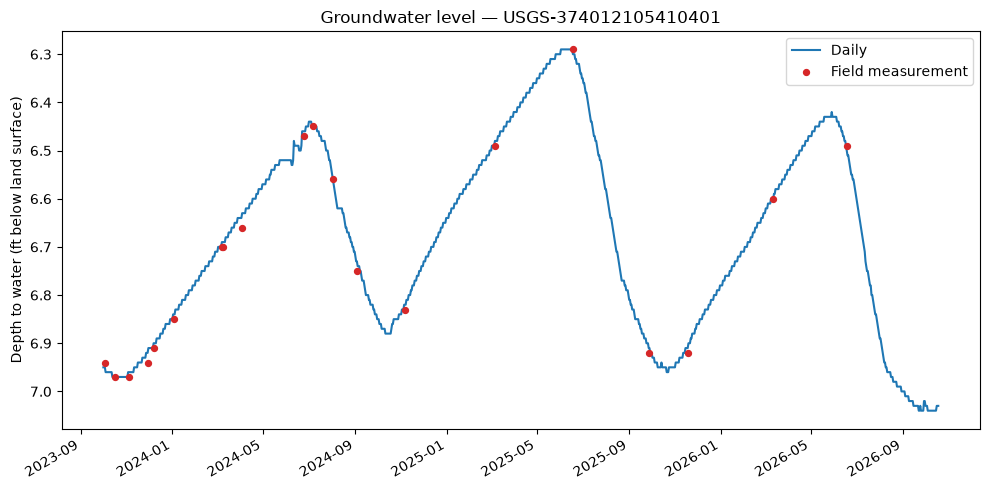

In [7]:
# Depth to water: invert y-axis so a falling water table plots downward
if daily_df.empty:
    print(f"No daily data returned for {example_site} in this date range.")
else:
    if "statistic_id" in daily_df.columns and daily_df["statistic_id"].nunique() > 1:
        print("Multiple statistics present, using mean (00003):", daily_df["statistic_id"].unique())
        daily_df = daily_df[daily_df["statistic_id"] == "00003"]

    field_df = get_gw_data(example_site, "field-measurements", begin=daily_df["time"].min().date().isoformat())

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(daily_df["time"], daily_df["value"], color="tab:blue", label="Daily")
    if not field_df.empty:
        ax.scatter(field_df["time"], field_df["value"], color="tab:red", s=18, zorder=3,
                   label="Field measurement")
    ax.invert_yaxis()
    ax.set_ylabel("Depth to water (ft below land surface)")
    ax.set_title(f"Groundwater level — {example_site}")
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

## 4. Compare several wells

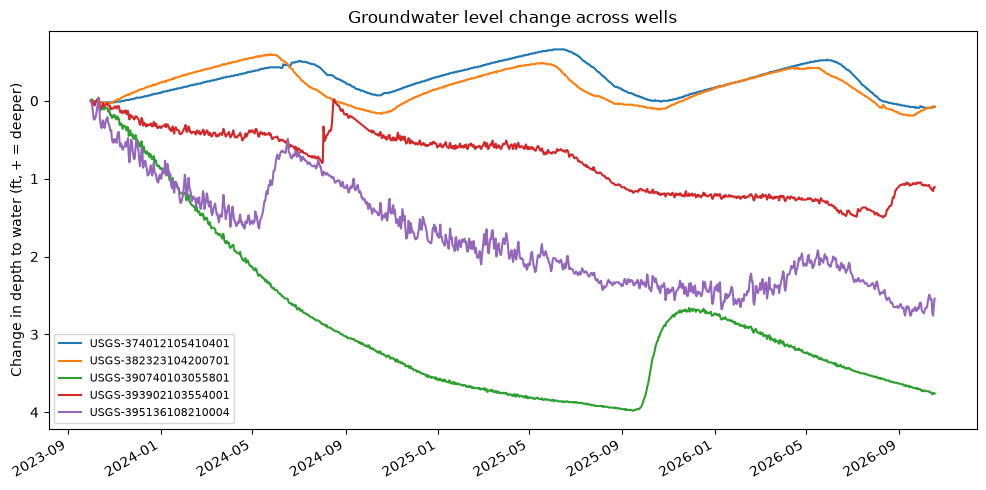

In [8]:
sample_sites = active["monitoring_location_id"].head(5).tolist() or [example_site]
multi_df = get_gw_daily(sample_sites, begin="2023-10-01")

if multi_df.empty:
    print("No data returned for these sites/date range.")
else:
    fig, ax = plt.subplots(figsize=(10, 5))
    for site, g in multi_df.groupby("monitoring_location_id"):
        # plot change relative to each well's first value so differently-deep wells are comparable
        ax.plot(g["time"], g["value"] - g["value"].iloc[0], label=site)
    ax.invert_yaxis()
    ax.set_ylabel("Change in depth to water (ft, + = deeper)")
    ax.set_title("Groundwater level change across wells")
    ax.legend(fontsize=8)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

## 5. Dashboard-ready snapshot

Builds one row per well: latest reading, how recent it is, and the change over the last 30 days. Writes `data/co_gw_latest.csv` and `.json`, which is what a GitHub Pages dashboard can read. Run this cell (or export it as a script) on a schedule to keep the dashboard fresh.

In [9]:
def change_over_window(site_ids, days=30):
    """Depth change vs. `days` ago from daily values (+ = water table deeper / falling)."""
    begin = (date.today() - timedelta(days=days + 5)).isoformat()
    df = get_gw_daily(site_ids, begin=begin)
    if df.empty:
        return pd.DataFrame(columns=["monitoring_location_id", f"change_{days}d_ft"])
    rows = []
    for site, g in df.groupby("monitoring_location_id"):
        g = g.dropna(subset=["value"])
        if len(g) < 2:
            continue
        target = g["time"].iloc[-1] - pd.Timedelta(days=days)
        base = g.iloc[(g["time"] - target).abs().argmin()]
        rows.append({"monitoring_location_id": site,
                     f"change_{days}d_ft": g["value"].iloc[-1] - base["value"]})
    return pd.DataFrame(rows)

# sensor wells get a 30-day change; manual-only wells just report their latest tape-down
site_ids = active["monitoring_location_id"].tolist()
latest = pd.concat([sensor_latest, manual_latest], ignore_index=True)
change = change_over_window(site_ids, days=30)
print(f"latest: {len(latest)} wells ({(latest['source'] == 'field-measurements').sum()} manual-only)")
if latest.empty:
    raise RuntimeError("No latest values for any well. Check the series/detail printout above: "
                       "the parameter code or collection names may differ for your sites.")

snapshot = (latest.merge(change, on="monitoring_location_id", how="left")
            .merge(co_sites[show].drop_duplicates("monitoring_location_id"), on="monitoring_location_id", how="left"))
snapshot["generated_utc"] = pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds")
print(f"{len(snapshot)} wells in snapshot")
snapshot.head()

latest: 238 wells (233 manual-only)
238 wells in snapshot


,monitoring_location_id,latest_time,latest_depth_ft,source,change_30d_ft,monitoring_location_name,altitude,latitude,longitude,generated_utc
0,USGS-374012105410401,2026-10-19 15:00:00+00:00,7.03,latest-continuous,0.00,NA04001232BAA RG42,7537.26,37.671139,-105.684889,2026-10-19T15:08:24+00:00
1,USGS-395136108210004,2026-10-19 14:45:00+00:00,60.51,latest-continuous,-0.16,SC00209824CBB4 TH75-13U,6398.99,39.860133,-108.350956,2026-10-19T15:08:24+00:00
2,USGS-393902103554001,2026-10-19 14:45:00+00:00,12.27,latest-continuous,0.03,SC00505806BBD1 DTX10A MUDDY CREEK,5120.00,39.650556,-103.927778,2026-10-19T15:08:24+00:00
3,USGS-390740103055801,2026-10-19 14:45:00+00:00,49.00,latest-continuous,0.08,SC01105103BAA1 LKWD RT WELL,5084.00,39.127771,-103.099936,2026-10-19T15:08:24+00:00
4,USGS-382323104200701,2026-10-19 14:00:00+00:00,22.34,latest-continuous,-0.12,"SC01906221AAA DROUGHT WELL NEAR PUEBLO, CO",4843.25,38.389672,-104.335817,2026-10-19T15:08:24+00:00


In [10]:
out_dir = Path("data")
out_dir.mkdir(exist_ok=True)
snapshot.to_csv(out_dir / "co_gw_latest.csv", index=False)
snapshot.to_json(out_dir / "co_gw_latest.json", orient="records", date_format="iso", indent=2)
print("Wrote", out_dir / "co_gw_latest.csv", "and", out_dir / "co_gw_latest.json")

Wrote data\co_gw_latest.csv and data\co_gw_latest.json
